# Notebook 07 — AdaBoost Baseline on FastText Embeddings (Amazon)
Tests whether AdaBoost ensembling over the same FastText sentence embeddings used
by COA-ANN provides any benefit. Pure CPU, sklearn only — no GPU needed.

**Inputs:** NB01 output (Amazon shared_data)
**Est. time:** ~20-30 minutes (CPU). AdaBoost is inherently sequential (each weak learner depends on the previous reweighting), so it runs on a single core regardless of CPU count. To keep runtime practical, AdaBoost is fit on a stratified 150k subsample of train+val; final evaluation uses the full 400k test set.


In [1]:
import os, random as _random, warnings, json, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
    matthews_corrcoef, average_precision_score, classification_report,
    precision_score, recall_score, confusion_matrix)

SEED = 42
DATASET = "amazon"

def set_seeds(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    _random.seed(seed)
    np.random.seed(seed)

set_seeds()

# ── Paths — UPDATE YOUR_USERNAME ──────────────────────────────────────────────
NB01_DIR     = "/kaggle/input/notebooks/abhaysharma01702/01-preprocessing"
NB01_SHARED  = f"{NB01_DIR}/shared_data/{DATASET}"
NB01_RESULTS = f"{NB01_DIR}/saved_results/{DATASET}"
NB04_DIR     = "/kaggle/input/notebooks/abhaysharma01702/04-final-training"
NB04_RESULTS = f"{NB04_DIR}/saved_results/{DATASET}"

WORKING     = "/kaggle/working"
RESULTS_DIR = f"{WORKING}/saved_results/{DATASET}"
os.makedirs(RESULTS_DIR, exist_ok=True)

print("Verifying NB01 outputs...")
required = ["X_emb_train.npy","X_emb_val.npy","X_emb_test.npy",
             "y_train.npy","y_val.npy","y_test.npy","config.json"]
for f in required:
    path = f"{NB01_SHARED}/{f}"
    print(f"  {'✓' if os.path.exists(path) else '✗ MISSING'} {f}")
print(f"SEED={SEED}  DATASET={DATASET}")


Verifying NB01 outputs...
  ✓ X_emb_train.npy
  ✓ X_emb_val.npy
  ✓ X_emb_test.npy
  ✓ y_train.npy
  ✓ y_val.npy
  ✓ y_test.npy
  ✓ config.json
SEED=42  DATASET=amazon


## 1. Load FastText Sentence Embeddings

In [2]:
X_emb_train = np.load(f"{NB01_SHARED}/X_emb_train.npy")
X_emb_val   = np.load(f"{NB01_SHARED}/X_emb_val.npy")
X_emb_test  = np.load(f"{NB01_SHARED}/X_emb_test.npy")
y_train = np.load(f"{NB01_SHARED}/y_train.npy")
y_val   = np.load(f"{NB01_SHARED}/y_val.npy")
y_test  = np.load(f"{NB01_SHARED}/y_test.npy")
cfg = json.load(open(f"{NB01_SHARED}/config.json"))

# Combine train+val
X_tv_full = np.vstack([X_emb_train, X_emb_val])
y_tv_full = np.concatenate([y_train, y_val])

print(f"Train+Val (full): {X_tv_full.shape}  Test: {X_emb_test.shape}")
print(f"Train+Val class balance: pos={y_tv_full.sum():,} ({100*y_tv_full.mean():.1f}%)  "
      f"neg={(y_tv_full==0).sum():,} ({100*(1-y_tv_full.mean()):.1f}%)")
print(f"Dataset imbalance ratio (from config): {cfg['imbalance_ratio']}")

# ── Stratified subsample for AdaBoost fitting ─────────────────────────────────
# AdaBoost is sequential (no parallelism across estimators), so fitting on the
# full 600k samples with 200+100 estimators would take ~4-5 hours on a single
# CPU core. A 150k stratified subsample keeps the class balance identical while
# reducing fit time to ~30 min total. Evaluation below still uses the FULL
# 400k test set, so reported metrics remain valid.
ADA_SUBSAMPLE_SIZE = 150_000

from sklearn.model_selection import train_test_split as _tts
if ADA_SUBSAMPLE_SIZE < len(y_tv_full):
    sub_idx, _ = _tts(
        np.arange(len(y_tv_full)), train_size=ADA_SUBSAMPLE_SIZE,
        stratify=y_tv_full, random_state=SEED)
    X_tv = X_tv_full[sub_idx]
    y_tv = y_tv_full[sub_idx]
else:
    X_tv, y_tv = X_tv_full, y_tv_full

print(f"\nAdaBoost training subsample: {X_tv.shape}  "
      f"(pos={y_tv.sum():,} / neg={(y_tv==0).sum():,})")


Train+Val (full): (600000, 300)  Test: (400000, 300)
Train+Val class balance: pos=300,000 (50.0%)  neg=300,000 (50.0%)
Dataset imbalance ratio (from config): 1.0

AdaBoost training subsample: (150000, 300)  (pos=75,000 / neg=75,000)


## 2. Evaluation Helper

In [3]:
def evaluate(name, y_true, y_pred, y_prob=None):
    auc = round(roc_auc_score(y_true, y_prob), 4) if y_prob is not None else float("nan")
    ap  = round(average_precision_score(y_true, y_prob), 4) if y_prob is not None else float("nan")
    rep = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    return {
        "Model"       : name,
        "Accuracy"    : round(accuracy_score(y_true, y_pred), 4),
        "Precision"   : round(precision_score(y_true, y_pred, zero_division=0), 4),
        "Recall"      : round(recall_score(y_true, y_pred, zero_division=0), 4),
        "F1-score"    : round(f1_score(y_true, y_pred, zero_division=0), 4),
        "Macro-F1"    : round(rep["macro avg"]["f1-score"], 4),
        "Weighted-F1" : round(rep["weighted avg"]["f1-score"], 4),
        "MCC"         : round(matthews_corrcoef(y_true, y_pred), 4),
        "AUC-ROC"     : auc, "Avg-Precision": ap,
    }

print("Evaluation helper ready.")


Evaluation helper ready.


## 3. Train AdaBoost Variants

In [4]:
results = []
probs   = {}

# ── Variant 1: AdaBoost with depth-1 stumps (classic AdaBoost) ───────────────
print("Training AdaBoost (depth-1 stumps, n_estimators=100)...")
print(f"Fitting on {len(y_tv):,} samples — est. ~10-15 min...")
set_seeds()
ada_stumps = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=SEED),
    n_estimators=100,
    learning_rate=1.0,
    random_state=SEED,
)
ada_stumps.fit(X_tv, y_tv)
prob_stumps = ada_stumps.predict_proba(X_emb_test)[:, 1]
pred_stumps = (prob_stumps > 0.5).astype(int)
r = evaluate("AdaBoost (depth-1, n=100)", y_test, pred_stumps, prob_stumps)
results.append(r); probs["ada_stumps"] = prob_stumps
print(f"  F1={r['F1-score']}  MCC={r['MCC']}  AUC={r['AUC-ROC']}")

# ── Variant 2: AdaBoost with depth-3 trees (stronger weak learners) ──────────
print(f"\nTraining AdaBoost (depth-3 trees, n_estimators=50)...")
print(f"Fitting on {len(y_tv):,} samples — est. ~10-15 min...")
set_seeds()
ada_depth3 = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=3, random_state=SEED),
    n_estimators=50,
    learning_rate=1.0,
    random_state=SEED,
)
ada_depth3.fit(X_tv, y_tv)
prob_depth3 = ada_depth3.predict_proba(X_emb_test)[:, 1]
pred_depth3 = (prob_depth3 > 0.5).astype(int)
r = evaluate("AdaBoost (depth-3, n=50)", y_test, pred_depth3, prob_depth3)
results.append(r); probs["ada_depth3"] = prob_depth3
print(f"  F1={r['F1-score']}  MCC={r['MCC']}  AUC={r['AUC-ROC']}")

print("\nBoth AdaBoost variants trained.")


Training AdaBoost (depth-1 stumps, n_estimators=100)...
Fitting on 150,000 samples — est. ~10-15 min...
  F1=0.7929  MCC=0.585  AUC=0.8758

Training AdaBoost (depth-3 trees, n_estimators=50)...
Fitting on 150,000 samples — est. ~10-15 min...
  F1=0.7934  MCC=0.5849  AUC=0.8754

Both AdaBoost variants trained.


## 4. Compare Against Existing Models

In [5]:
# Load existing results for comparison (graceful if missing)
def try_load_metrics(path, label):
    if os.path.exists(path):
        m = json.load(open(path))
        return m
    print(f"  Not found: {label} ({path})")
    return None

comparison_rows = list(results)  # AdaBoost results

baseline_metrics = try_load_metrics(f"{NB01_RESULTS}/baseline_metrics.json", "NB01 baselines")
if baseline_metrics:
    for name in ["TF-IDF + LR", "TF-IDF + SVM", "Default ANN", "Default CNN+BiLSTM"]:
        if name in baseline_metrics:
            comparison_rows.append({"Model": name, **baseline_metrics[name]})

ann_coa_metrics = try_load_metrics(f"{NB04_RESULTS}/ann_coa_metrics.json", "NB04 COA-ANN")
if ann_coa_metrics:
    row = {k:v for k,v in ann_coa_metrics.items()
           if k in ["Accuracy","Precision","Recall","F1-score","Macro-F1",
                     "Weighted-F1","MCC","AUC-ROC","Avg-Precision"]}
    comparison_rows.append({"Model": "COA-ANN", **row})

cnn_coa_metrics = try_load_metrics(f"{NB04_RESULTS}/cnn_coa_metrics.json", "NB04 COA-CNN+BiLSTM")
if cnn_coa_metrics:
    row = {k:v for k,v in cnn_coa_metrics.items()
           if k in ["Accuracy","Precision","Recall","F1-score","Macro-F1",
                     "Weighted-F1","MCC","AUC-ROC","Avg-Precision"]}
    comparison_rows.append({"Model": "COA-CNN+BiLSTM", **row})

comp_df = (pd.DataFrame(comparison_rows)
             .sort_values("F1-score", ascending=False)
             .reset_index(drop=True))
comp_df.index += 1
print("=== Full Comparison (Amazon test set) ===\n")
print(comp_df[["Model","Accuracy","F1-score","Macro-F1","MCC","AUC-ROC"]].to_string())


=== Full Comparison (Amazon test set) ===

                       Model  Accuracy  F1-score  Macro-F1     MCC  AUC-ROC
1               TF-IDF + SVM    0.9097    0.9099    0.9097  0.8194   0.9693
2                TF-IDF + LR    0.9093    0.9097    0.9093  0.8187   0.9689
3             COA-CNN+BiLSTM    0.8917    0.8940    0.8916  0.7842   0.9603
4         Default CNN+BiLSTM    0.8884    0.8875    0.8884  0.7769   0.9573
5                Default ANN    0.8686    0.8680    0.8686  0.7371   0.9424
6                    COA-ANN    0.8670    0.8660    0.8670  0.7342   0.9411
7   AdaBoost (depth-3, n=50)    0.7924    0.7934    0.7924  0.5849   0.8754
8  AdaBoost (depth-1, n=100)    0.7925    0.7929    0.7925  0.5850   0.8758


## 5. Plot Comparison

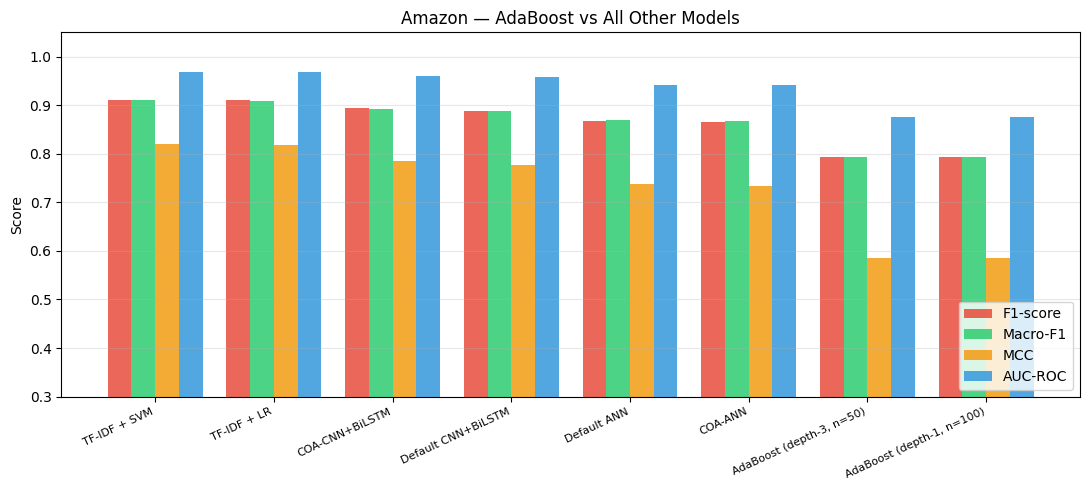

In [6]:
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(comp_df)); w = 0.2
for i,(m,c) in enumerate(zip(["F1-score","Macro-F1","MCC","AUC-ROC"],
                               ["#e74c3c","#2ecc71","#f39c12","#3498db"])):
    ax.bar(x+i*w, comp_df[m], w, label=m, color=c, alpha=0.85)
ax.set_xticks(x+1.5*w)
ax.set_xticklabels(comp_df["Model"], rotation=25, ha="right", fontsize=8)
ax.set_ylim(0.3, 1.05); ax.set_ylabel("Score")
ax.set_title("Amazon — AdaBoost vs All Other Models")
ax.legend(loc="lower right"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
os.makedirs(f"{RESULTS_DIR}", exist_ok=True)
plt.savefig(f"{RESULTS_DIR}/fig_adaboost_comparison.pdf", dpi=300, bbox_inches="tight")
plt.show()


## 6. Save Results

In [7]:
# Save AdaBoost predictions and metrics
np.save(f"{RESULTS_DIR}/ada_stumps_prob.npy", probs["ada_stumps"])
np.save(f"{RESULTS_DIR}/ada_depth3_prob.npy", probs["ada_depth3"])

pd.DataFrame(results).to_csv(f"{RESULTS_DIR}/adaboost_metrics.csv", index=False)
json.dump({r["Model"]: {k:v for k,v in r.items() if k!="Model"} for r in results},
          open(f"{RESULTS_DIR}/adaboost_metrics.json","w"), indent=2)

comp_df.to_csv(f"{RESULTS_DIR}/adaboost_full_comparison.csv")

print("=== Summary ===")
for r in results:
    print(f"  {r['Model']:28s}: F1={r['F1-score']}  MCC={r['MCC']}  AUC={r['AUC-ROC']}")

best_ada = max(results, key=lambda r: r["F1-score"])
print(f"\nBest AdaBoost variant: {best_ada['Model']} (F1={best_ada['F1-score']})")

if ann_coa_metrics:
    coa_f1 = ann_coa_metrics["F1-score"]
    print(f"COA-ANN F1: {coa_f1}")
    diff = best_ada["F1-score"] - coa_f1
    if diff > 0:
        print(f"AdaBoost beats COA-ANN by {diff:+.4f} F1")
    else:
        print(f"AdaBoost underperforms COA-ANN by {diff:+.4f} F1")

print(f"\nSaved to {RESULTS_DIR}/")
for f in sorted(os.listdir(RESULTS_DIR)):
    print(f"  ✓ {f}")


=== Summary ===
  AdaBoost (depth-1, n=100)   : F1=0.7929  MCC=0.585  AUC=0.8758
  AdaBoost (depth-3, n=50)    : F1=0.7934  MCC=0.5849  AUC=0.8754

Best AdaBoost variant: AdaBoost (depth-3, n=50) (F1=0.7934)
COA-ANN F1: 0.866
AdaBoost underperforms COA-ANN by -0.0726 F1

Saved to /kaggle/working/saved_results/amazon/
  ✓ ada_depth3_prob.npy
  ✓ ada_stumps_prob.npy
  ✓ adaboost_full_comparison.csv
  ✓ adaboost_metrics.csv
  ✓ adaboost_metrics.json
  ✓ fig_adaboost_comparison.pdf
